In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv('/content/ai_jobs_market_2025_2026.csv')

In [3]:

data.head()

,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,ai_salary_premium_pct,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier
0,AIJOB0001,AI Agent Developer,AI Engineering,Senior (6-9 yrs),7,Master's,239000.0,155000,290000,Boston,...,13.1,96,16.9,6.8,2026,3,1,0,1,Senior ($200-300k)
1,AIJOB0002,Prompt Engineer,AI Engineering,Senior (6-9 yrs),2,Bachelor's,166000.0,90000,200000,London,...,5.4,82,11.6,6.2,2026,1,1,1,1,Upper-Mid ($150-200k)
2,AIJOB0003,LLM Engineer,AI Engineering,Senior (6-9 yrs),4,Associate's,360000.0,160000,300000,Seattle,...,9.1,98,42.7,7.7,2026,1,1,1,1,Elite (>$300k)
3,AIJOB0004,Data Engineer (AI),Data Engineering,Senior (6-9 yrs),3,Bachelor's,161000.0,130000,220000,Singapore,...,12.0,88,6.7,9.5,2026,3,1,1,0,Upper-Mid ($150-200k)
4,AIJOB0005,AI Product Manager,Product,Lead (10+ yrs),5,Bootcamp/Self-taught,283000.0,140000,260000,Los Angeles,...,9.4,85,17.3,8.9,2026,1,1,1,0,Senior ($200-300k)


In [4]:

data.tail()

,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,ai_salary_premium_pct,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier
1495,AIJOB1496,Multimodal AI Engineer,AI Engineering,Lead (10+ yrs),8,Master's,262000.0,160000,300000,Toronto,...,8.8,90,23.6,7.5,2026,1,1,1,0,Senior ($200-300k)
1496,AIJOB1497,NLP Engineer,AI Engineering,Senior (6-9 yrs),9,Bootcamp/Self-taught,163000.0,145000,290000,Berlin,...,6.7,91,66.5,7.8,2025,3,1,0,0,Upper-Mid ($150-200k)
1497,AIJOB1498,AI Compliance Manager,Governance,Mid (3-5 yrs),10,Master's,127000.0,100000,200000,Zurich,...,10.9,68,15.3,8.3,2026,3,0,1,0,Mid ($100-150k)
1498,AIJOB1499,NLP Engineer,AI Engineering,Lead (10+ yrs),4,Bachelor's,145000.0,145000,290000,Bangalore,...,8.5,91,78.8,7.4,2025,5,1,1,0,Mid ($100-150k)
1499,AIJOB1500,AI Security Engineer,Security,Lead (10+ yrs),5,Master's,229000.0,140000,260000,Berlin,...,12.2,80,9.0,8.6,2025,6,1,1,0,Senior ($200-300k)


In [5]:

data.shape

(1500, 25)

In [6]:

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   job_id                 1500 non-null   object 
 1   job_title              1500 non-null   object 
 2   job_category           1500 non-null   object 
 3   experience_level       1500 non-null   object 
 4   years_of_experience    1500 non-null   int64  
 5   education_required     1500 non-null   object 
 6   annual_salary_usd      1500 non-null   float64
 7   salary_min_usd         1500 non-null   int64  
 8   salary_max_usd         1500 non-null   int64  
 9   city                   1500 non-null   object 
 10  country                1500 non-null   object 
 11  remote_work            1500 non-null   object 
 12  company_size           1500 non-null   object 
 13  industry               1500 non-null   object 
 14  required_skills        1500 non-null   object 
 15  ai_s

In [7]:

data.describe()

,years_of_experience,annual_salary_usd,salary_min_usd,salary_max_usd,ai_salary_premium_pct,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,6.216000,194892.000000,135448.666667,257537.333333,10.858200,87.523333,31.116333,7.897333,2025.584000,3.968000,0.496667,0.754000,0.218000
std,2.675216,66506.822013,24448.950878,39852.822207,4.029742,8.026315,22.046343,1.102846,0.493058,3.270388,0.500156,0.430822,0.413025
min,1.000000,90000.000000,90000.000000,180000.000000,3.000000,68.000000,5.000000,6.000000,2025.000000,1.000000,0.000000,0.000000,0.000000
25%,4.000000,144750.000000,120000.000000,218000.000000,8.200000,82.000000,15.375000,6.900000,2025.000000,2.000000,0.000000,1.000000,0.000000
50%,6.000000,180000.000000,140000.000000,270000.000000,10.500000,89.000000,23.400000,7.900000,2026.000000,3.000000,0.000000,1.000000,0.000000
75%,8.000000,236250.000000,155000.000000,290000.000000,14.200000,95.000000,42.700000,8.900000,2026.000000,5.000000,1.000000,1.000000,0.000000
max,15.000000,384000.000000,180000.000000,320000.000000,18.000000,98.000000,87.800000,9.800000,2026.000000,12.000000,1.000000,1.000000,1.000000


In [8]:

data.min(numeric_only=True)

,0
years_of_experience,1.0
annual_salary_usd,90000.0
salary_min_usd,90000.0
salary_max_usd,180000.0
ai_salary_premium_pct,3.0
demand_score,68.0
demand_growth_yoy_pct,5.0
benefits_score_10,6.0
posting_year,2025.0
posting_month,1.0


In [9]:

data.max(numeric_only=True)

,0
years_of_experience,15.0
annual_salary_usd,384000.0
salary_min_usd,180000.0
salary_max_usd,320000.0
ai_salary_premium_pct,18.0
demand_score,98.0
demand_growth_yoy_pct,87.8
benefits_score_10,9.8
posting_year,2026.0
posting_month,12.0


In [10]:

data['salary_max_usd'].unique()

array([290000, 200000, 300000, 220000, 260000, 312000, 320000, 280000,
       295000, 270000, 180000, 240000, 218000, 210000, 250000, 195000])

In [11]:

data['years_of_experience'].value_counts()

,count
years_of_experience,
6,208
7,197
5,178
8,174
3,166
4,166
9,120
2,99
10,98


In [12]:

data.isnull().sum()

,0
job_id,0
job_title,0
job_category,0
experience_level,0
years_of_experience,0
education_required,0
annual_salary_usd,0
salary_min_usd,0
salary_max_usd,0
city,0


In [13]:

data.isnull().sum()

,0
job_id,0
job_title,0
job_category,0
experience_level,0
years_of_experience,0
education_required,0
annual_salary_usd,0
salary_min_usd,0
salary_max_usd,0
city,0


In [14]:

data.mean(numeric_only=True)

,0
years_of_experience,6.216000
annual_salary_usd,194892.000000
salary_min_usd,135448.666667
salary_max_usd,257537.333333
ai_salary_premium_pct,10.858200
demand_score,87.523333
demand_growth_yoy_pct,31.116333
benefits_score_10,7.897333
posting_year,2025.584000
posting_month,3.968000


In [15]:

data.duplicated().sum()

np.int64(0)

In [16]:

data = data.drop_duplicates()

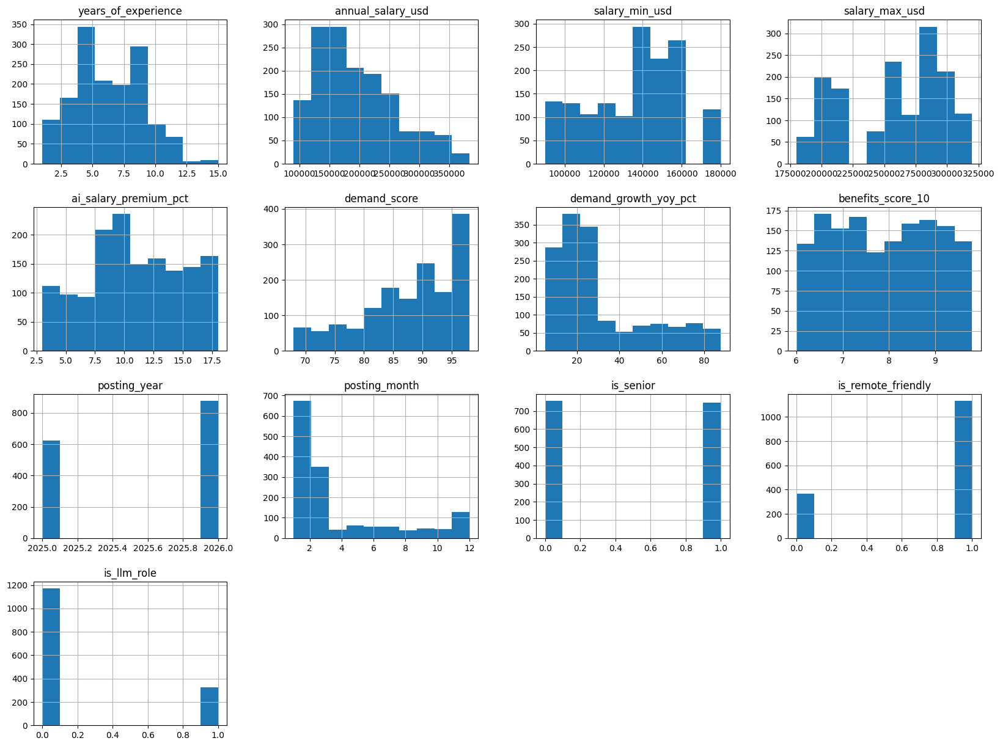

In [17]:
data.hist(figsize=(20, 15))
plt.show()

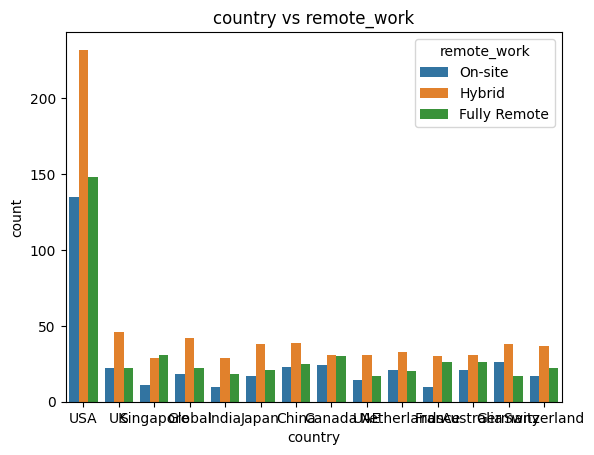

In [18]:
sns.countplot(x='country',hue='remote_work' ,data=data)
plt.title('country vs remote_work')
plt.show()





In [19]:
sns.countplot(x='job_title',hue='required_skills' ,data=data)
plt.title('job_title vs required_skills')
plt.show()

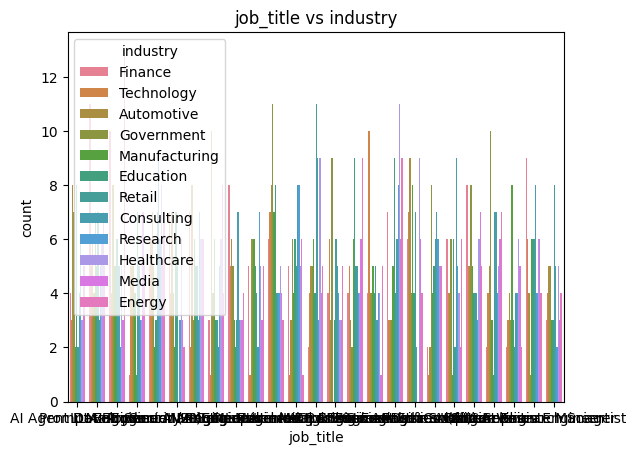

In [20]:


sns.countplot(x='job_title',hue='industry' ,data=data)
plt.title('job_title vs industry')
plt.show()